## Checking if triangular inequality is fulfilled

In [66]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [67]:
from pathlib import Path
import pyrootutils
import os

notebook_path = Path(os.path.abspath(""))
pyrootutils.setup_root(notebook_path, indicator=".project-root", pythonpath=True)

WindowsPath('C:/Users/victo/Documents/ETH/pa-covariate-shift')

In [68]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset
from pametric.datautils import MultienvDataset
from pametric.metrics import PosteriorAgreement

import matplotlib.pyplot as plt

In [ ]:
f_logits = lambda pred, conf: torch.tensor([-conf, conf]) if pred == 1 else torch.tensor([conf, -conf])
f_tensordataset = lambda preds, confs: TensorDataset(
    torch.stack(
        [
            f_logits(p, float(c))
            for p, c in zip(preds, confs)
        ],
        dim=0
    ),
    torch.tensor(preds)
)

yp = f_tensordataset([0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [1, 3, 2, 2, 2, 2, 2, 2, 2, 2])
ypp = f_tensordataset([1, 0, 0, 0, 0, 0, 0, 0, 0, 0], [1, 3, 2, 2, 2, 2, 2, 2, 2, 2])
yppp = f_tensordataset([1, 1, 0, 0, 0, 0, 0, 0, 0, 0], [3, 1, 1, 1, 1, 1, 1, 1, 1, 1])

ds_p_pp = MultienvDataset([yp, ypp])
ds_pp_ppp = MultienvDataset([ypp, yppp])
ds_p_ppp = MultienvDataset([yp, yppp])

In [703]:
simple_collate_fn = lambda batch: {env: b for env, b in enumerate(batch)}

pa_epochs = 200
pa_p_pp = PosteriorAgreement(
    dataset=ds_p_pp,
    pa_epochs=pa_epochs,
    beta0=1.0,
    collate_fn=simple_collate_fn
)
pa_p_pp.update(nn.Identity())
out_p_pp = pa_p_pp.compute()

pa_pp_ppp = PosteriorAgreement(
    dataset=ds_pp_ppp,
    pa_epochs=pa_epochs,
    beta0=1.0,
    collate_fn=simple_collate_fn
)
pa_pp_ppp.update(nn.Identity())
out_pp_ppp = pa_pp_ppp.compute()

pa_p_ppp = PosteriorAgreement(
    dataset=ds_p_ppp,
    pa_epochs=pa_epochs,
    beta0=1.0,
    collate_fn=simple_collate_fn
)
pa_p_ppp.update(nn.Identity())
out_p_ppp = pa_p_ppp.compute()

In [704]:
out_p_pp[0]['beta'], out_pp_ppp[0]['beta'], out_p_ppp[0]['beta']

(0.9589704275131226, 1.1393539905548096, 0.7915482521057129)

In [705]:
out_p_pp[0]["logPA"], out_pp_ppp[0]["logPA"], out_p_ppp[0]["logPA"], -out_p_pp[0]["logPA"] - out_pp_ppp[0]["logPA"] < -out_p_ppp[0]["logPA"]

(-1.8790909051895142, -3.2425317764282227, -5.117082595825195, False)

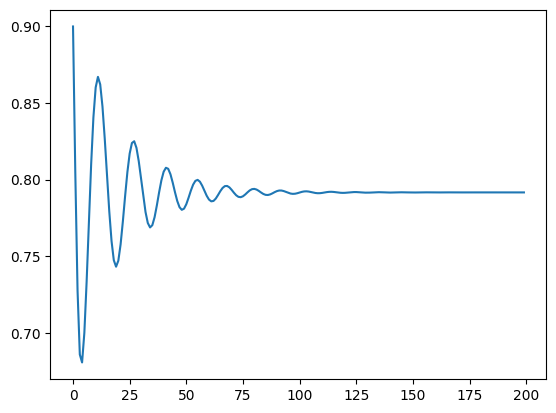

In [706]:
plt.plot(pa_p_ppp.betas)

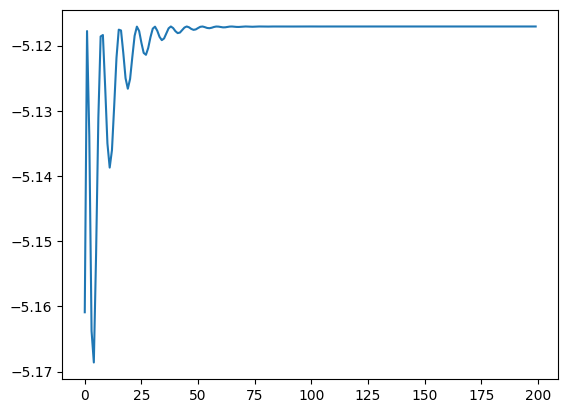

In [707]:
plt.plot(pa_p_ppp.logPAs.squeeze().numpy())